In [4]:
import librosa
import numpy as np
from pathlib import Path

filepaths = list(Path("daria-recordings/calm-onset-test").glob("*.wav"))
print(f"Found {len(filepaths)} recordings")

def extract_windows(feature_array, window_size=20, step=1):
    windows = []
    for i in range(0, len(feature_array) - window_size, step):
        windows.append(feature_array[i:i + window_size])
    return np.array(windows)

all_onset_windows = []
for fp in filepaths:
    y, sr = librosa.load(str(fp), sr=44100, mono=True)
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    windows = extract_windows(onset_env)
    all_onset_windows.append(windows)

all_onset_windows = np.vstack(all_onset_windows)
print("Total windows:", all_onset_windows.shape)

Found 10 recordings
Total windows: (21346, 20)


In [5]:
import librosa
import numpy as np
from pathlib import Path
from sklearn import preprocessing

filepaths = list(Path("daria-recordings/calm-onset-test").glob("*.wav"))
print(f"Found {len(filepaths)} recordings")

def extract_windows(feature_array, window_size=20, step=1):
    windows = []
    for i in range(0, len(feature_array) - window_size, step):
        windows.append(feature_array[i:i + window_size])
    return np.array(windows)

all_onset_windows = []
for fp in filepaths:
    y, sr = librosa.load(str(fp), sr=44100, mono=True)
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    windows = extract_windows(onset_env)
    all_onset_windows.append(windows)

all_onset_windows = np.vstack(all_onset_windows)
print("Total windows:", all_onset_windows.shape)

onset_scaler = preprocessing.MinMaxScaler()
onset_scaled_test = onset_scaler.fit_transform(all_onset_windows)
print("Scaled, ready to train")

Found 10 recordings
Total windows: (21346, 20)
Scaled, ready to train


In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

class WindowAutoencoder(nn.Module):
    def __init__(self, input_dim=20, latent_dim=2, hidden_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, input_dim))
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

tensor_data = torch.tensor(onset_scaled_test, dtype=torch.float32)
dataset = TensorDataset(tensor_data)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

model_onset_test = WindowAutoencoder()
optimizer = torch.optim.Adam(model_onset_test.parameters(), lr=1e-4)

for epoch in range(100):
    for batch in dataloader:
        x = batch[0]
        recon_x, z = model_onset_test(x)
        loss = F.mse_loss(recon_x, x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    if epoch % 20 == 0:
        print(f"Epoch {epoch}, loss: {loss.item():.6f}")

torch.save(model_onset_test.state_dict(), "onset_autoencoder_calm_test.pt")
print("Saved test model")

Epoch 0, loss: 0.026276
Epoch 20, loss: 0.002768
Epoch 40, loss: 0.003234
Epoch 60, loss: 0.002358
Epoch 80, loss: 0.002238
Saved test model


In [7]:
baseline_onset_test = model_onset_test.encoder(
    torch.tensor(onset_scaled_test, dtype=torch.float32)
).detach().numpy().mean(axis=0)

print("Baseline (calm-only):", baseline_onset_test)

Baseline (calm-only): [-0.0061789   0.20148839]


In [8]:
import sounddevice as sd
print(sd.query_devices())

< 0 Scarlett 4i4 USB, Core Audio (6 in, 4 out)
> 1 MacBook Pro Microphone, Core Audio (1 in, 0 out)
  2 MacBook Pro Speakers, Core Audio (0 in, 2 out)
  3 iPhone (2) Microphone, Core Audio (1 in, 0 out)
  4 Microsoft Teams Audio, Core Audio (1 in, 1 out)
  5 ZoomAudioDevice, Core Audio (2 in, 2 out)


In [ ]:
model_onset_test = WindowAutoencoder()
model_onset_test.load_state_dict(torch.load("onset_autoencoder_calm_test.pt"))
model_onset_test.eval()


baseline_onset_test = model_onset_test.encoder(
    torch.tensor(onset_scaled_test, dtype=torch.float32)
).detach().numpy().mean(axis=0)

In [10]:
import sounddevice as sd
from collections import deque
import numpy as np

sd.default.device = [0, None]

sr = 44100
block_size = 512
window_size = 20
audio_history_size = 4096

onset_buffer = deque(maxlen=window_size)
audio_history = deque(maxlen=audio_history_size)

def test_callback(indata, frames, time, status):
    y = indata[:, 0]
    audio_history.extend(y)
    
    if len(audio_history) == audio_history_size:
        y_history = np.array(audio_history)
        onset_env = librosa.onset.onset_strength(y=y_history, sr=sr, hop_length=block_size)
        onset_val = onset_env[-1] if len(onset_env) > 0 else 0.0
    else:
        onset_val = 0.0
    
    onset_buffer.append(onset_val)
    
    if len(onset_buffer) == window_size:
        with torch.no_grad():
            _, z = model_onset_test(torch.tensor(np.array(onset_buffer), dtype=torch.float32).unsqueeze(0))
        deviation = np.linalg.norm(z.flatten().numpy() - baseline_onset_test)
        print(f"onset deviation: {deviation:.4f}")

with sd.InputStream(samplerate=sr, blocksize=block_size, channels=1, device=0, callback=test_callback):
    print("Listening... play calm first, then busy")
    sd.sleep(30000)

Listening... play calm first, then busy
onset deviation: 4.7956
onset deviation: 4.7502
onset deviation: 5.0984
onset deviation: 4.9128
onset deviation: 4.8108
onset deviation: 4.7080
onset deviation: 4.6000
onset deviation: 4.5384
onset deviation: 4.6385
onset deviation: 4.5717
onset deviation: 4.4816
onset deviation: 4.3883
onset deviation: 4.5235
onset deviation: 4.6294
onset deviation: 4.7515
onset deviation: 4.8909
onset deviation: 4.9523
onset deviation: 5.0184
onset deviation: 4.9405
onset deviation: 4.8174
onset deviation: 4.8552
onset deviation: 4.7414
onset deviation: 4.7350
onset deviation: 4.7378
onset deviation: 4.6853
onset deviation: 4.9200
onset deviation: 5.0374
onset deviation: 4.7931
onset deviation: 5.0231
onset deviation: 5.0069
onset deviation: 4.6501
onset deviation: 4.7020
onset deviation: 4.6720
onset deviation: 4.5920
onset deviation: 4.8831
onset deviation: 4.6894
onset deviation: 4.9499
onset deviation: 5.2147
onset deviation: 5.3868
onset deviation: 7.0378


KeyboardInterrupt: 

In [11]:
import sounddevice as sd
from collections import deque
import numpy as np
import torch
import librosa

sd.default.device = [0, None]

sr = 44100
block_size = 512
window_size = 20
audio_history_size = 4096

onset_buffer = deque(maxlen=window_size)
audio_history = deque(maxlen=audio_history_size)
onset_deviation_log = []

def test_callback(indata, frames, time, status):
    y = indata[:, 0]
    audio_history.extend(y)
    
    if len(audio_history) == audio_history_size:
        y_history = np.array(audio_history)
        onset_env = librosa.onset.onset_strength(y=y_history, sr=sr, hop_length=block_size)
        onset_val = onset_env[-1] if len(onset_env) > 0 else 0.0
    else:
        onset_val = 0.0
    
    onset_buffer.append(onset_val)
    
    if len(onset_buffer) == window_size:
        with torch.no_grad():
            _, z = model_onset_test(torch.tensor(np.array(onset_buffer), dtype=torch.float32).unsqueeze(0))
        deviation = np.linalg.norm(z.flatten().numpy() - baseline_onset_test)
        onset_deviation_log.append(deviation)

with sd.InputStream(samplerate=sr, blocksize=block_size, channels=1, device=0, callback=test_callback):
    print("Listening... play calm for ~15 sec, then busy for ~15 sec")
    sd.sleep(30000)

print("Done. Total readings:", len(onset_deviation_log))

Listening... play calm for ~15 sec, then busy for ~15 sec
Done. Total readings: 2573


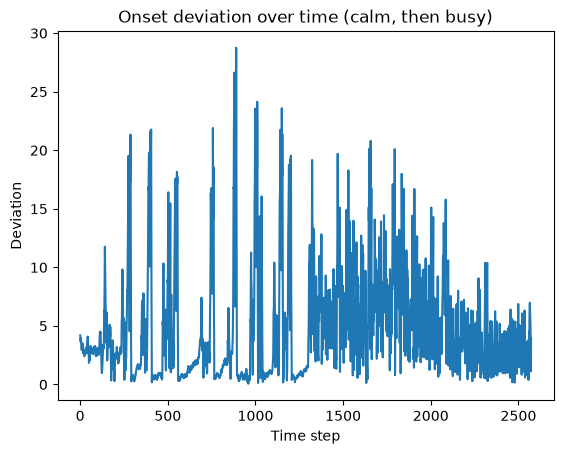

First half (calm) average: 4.226144
Second half (busy) average: 5.8761945


In [12]:
import matplotlib.pyplot as plt
plt.plot(onset_deviation_log)
plt.title("Onset deviation over time (calm, then busy)")
plt.xlabel("Time step")
plt.ylabel("Deviation")
plt.show()

print("First half (calm) average:", np.mean(onset_deviation_log[:len(onset_deviation_log)//2]))
print("Second half (busy) average:", np.mean(onset_deviation_log[len(onset_deviation_log)//2:]))

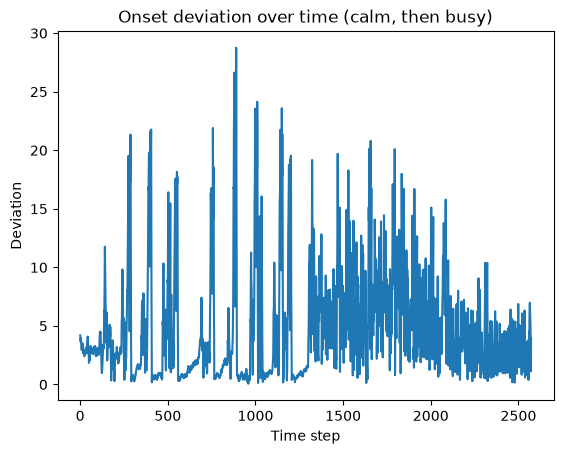

First half (calm) average: 4.226144
Second half (busy) average: 5.8761945


In [13]:
import matplotlib.pyplot as plt
plt.plot(onset_deviation_log)
plt.title("Onset deviation over time (calm, then busy)")
plt.xlabel("Time step")
plt.ylabel("Deviation")
plt.show()

print("First half (calm) average:", np.mean(onset_deviation_log[:len(onset_deviation_log)//2]))
print("Second half (busy) average:", np.mean(onset_deviation_log[len(onset_deviation_log)//2:]))

In [23]:
import soundfile as sf
from pathlib import Path
from datetime import datetime
import sounddevice as sd

sd.default.device = [0, None]

test_folder = Path("daria-recordings/calm-onset-test-v2")
test_folder.mkdir(exist_ok=True, parents=True)

filename = test_folder / f"calm_{datetime.now().strftime('%Y%m%d_%H%M%S')}.wav"
test_file = sf.SoundFile(str(filename), mode='w', samplerate=44100, channels=1)
print("Recording to:", filename)

def simple_callback(indata, frames, time, status):
    test_file.write(indata[:, 0])

try:
    with sd.InputStream(samplerate=44100, blocksize=512, channels=1, device=0, callback=simple_callback):
        print("Recording... play VERY calmly, sustained notes only")
        sd.sleep(25000)
except KeyboardInterrupt:
    pass
finally:
    test_file.close()

Recording to: daria-recordings/calm-onset-test-v2/calm_20260905_134731.wav
Recording... play VERY calmly, sustained notes only


In [25]:
import librosa
import numpy as np
from pathlib import Path
from sklearn import preprocessing

filepaths = list(Path("daria-recordings/calm-onset-test-v2").glob("*.wav"))
print(f"Found {len(filepaths)} recordings")

def extract_windows(feature_array, window_size=20, step=1):
    windows = []
    for i in range(0, len(feature_array) - window_size, step):
        windows.append(feature_array[i:i + window_size])
    return np.array(windows)

all_onset_windows = []
for fp in filepaths:
    y, sr = librosa.load(str(fp), sr=44100, mono=True)
    onset_env = librosa.onset.onset_strength(y=y, sr=sr)
    windows = extract_windows(onset_env)
    all_onset_windows.append(windows)

all_onset_windows = np.vstack(all_onset_windows)
print("Total windows:", all_onset_windows.shape)

onset_scaler = preprocessing.MinMaxScaler()
onset_scaled_test = onset_scaler.fit_transform(all_onset_windows)
print("Scaled, ready to train")

Found 10 recordings
Total windows: (21410, 20)
Scaled, ready to train


In [26]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

class WindowAutoencoder(nn.Module):
    def __init__(self, input_dim=20, latent_dim=2, hidden_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, input_dim))
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

tensor_data = torch.tensor(onset_scaled_test, dtype=torch.float32)
dataset = TensorDataset(tensor_data)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

model_onset_test = WindowAutoencoder()
optimizer = torch.optim.Adam(model_onset_test.parameters(), lr=1e-4)

for epoch in range(100):
    for batch in dataloader:
        x = batch[0]
        recon_x, z = model_onset_test(x)
        loss = F.mse_loss(recon_x, x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    if epoch % 20 == 0:
        print(f"Epoch {epoch}, loss: {loss.item():.6f}")

torch.save(model_onset_test.state_dict(), "onset_autoencoder_calm_test_v2.pt")
print("Saved test model v2")

Epoch 0, loss: 0.022641
Epoch 20, loss: 0.000837
Epoch 40, loss: 0.001761
Epoch 60, loss: 0.001058
Epoch 80, loss: 0.000820
Saved test model v2


In [27]:
baseline_onset_test = model_onset_test.encoder(
    torch.tensor(onset_scaled_test, dtype=torch.float32)
).detach().numpy().mean(axis=0)

print("Baseline (strict calm-only, v2):", baseline_onset_test)

Baseline (strict calm-only, v2): [ 0.05014079 -0.2775618 ]


In [28]:
import sounddevice as sd
from collections import deque
import numpy as np
import torch
import librosa

sd.default.device = [0, None]

sr = 44100
block_size = 512
window_size = 20
audio_history_size = 4096

onset_buffer = deque(maxlen=window_size)
audio_history = deque(maxlen=audio_history_size)
onset_deviation_log = []

def test_callback(indata, frames, time, status):
    y = indata[:, 0]
    audio_history.extend(y)
    
    if len(audio_history) == audio_history_size:
        y_history = np.array(audio_history)
        onset_env = librosa.onset.onset_strength(y=y_history, sr=sr, hop_length=block_size)
        onset_val = onset_env[-1] if len(onset_env) > 0 else 0.0
    else:
        onset_val = 0.0
    
    onset_buffer.append(onset_val)
    
    if len(onset_buffer) == window_size:
        with torch.no_grad():
            _, z = model_onset_test(torch.tensor(np.array(onset_buffer), dtype=torch.float32).unsqueeze(0))
        deviation = np.linalg.norm(z.flatten().numpy() - baseline_onset_test)
        onset_deviation_log.append(deviation)

with sd.InputStream(samplerate=sr, blocksize=block_size, channels=1, device=0, callback=test_callback):
    print("Starting in 3... 2... 1...")
    print("CALM for 10 sec")
    sd.sleep(10000)
    print("STOP - silence for 3 sec")
    sd.sleep(3000)
    print("BUSY for 10 sec")
    sd.sleep(10000)
    print("STOP")

print("Done. Total readings:", len(onset_deviation_log))

Starting in 3... 2... 1...
CALM for 10 sec
STOP - silence for 3 sec
BUSY for 10 sec
STOP
Done. Total readings: 1965


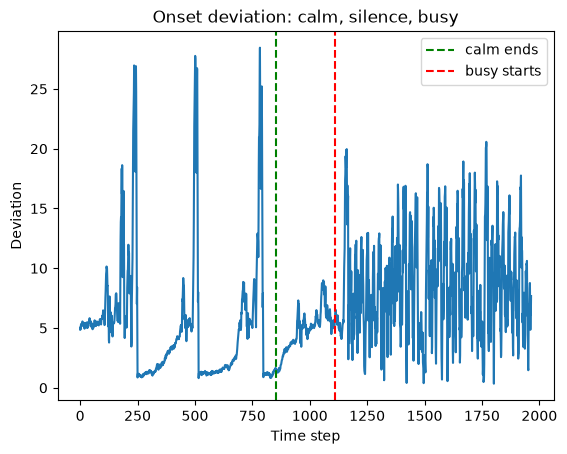

In [29]:
import matplotlib.pyplot as plt

plt.plot(onset_deviation_log)
plt.axvline(x=len(onset_deviation_log) * (10/23), color='green', linestyle='--', label='calm ends')
plt.axvline(x=len(onset_deviation_log) * (13/23), color='red', linestyle='--', label='busy starts')
plt.title("Onset deviation: calm, silence, busy")
plt.xlabel("Time step")
plt.ylabel("Deviation")
plt.legend()
plt.show()

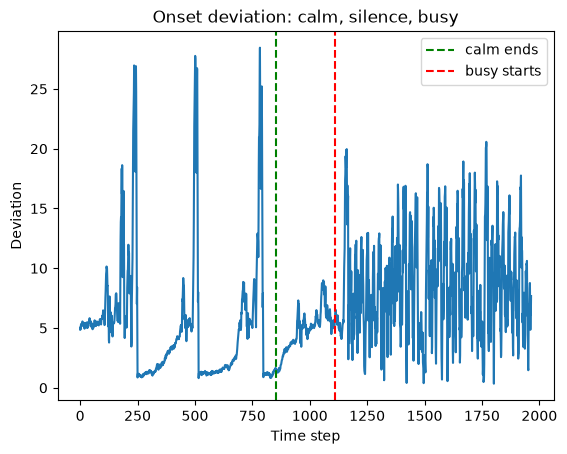

Calm - median: 4.5385365 std: 5.2917957
Busy - median: 8.224953 std: 4.1842494


In [ ]:
import matplotlib.pyplot as plt

plt.plot(onset_deviation_log)
plt.axvline(x=len(onset_deviation_log) * (10/23), color='green', linestyle='--', label='calm ends')
plt.axvline(x=len(onset_deviation_log) * (13/23), color='red', linestyle='--', label='busy starts')
plt.title("Onset deviation: calm, silence, busy")
plt.xlabel("Time step")
plt.ylabel("Deviation")
plt.legend()
plt.show()

# Rough split based on timing proportions (10s calm, 3s silence, 10s busy out of 23s total)
n = len(onset_deviation_log)
calm_end = int(n * 10/23)
busy_start = int(n * 13/23)

calm_vals = onset_deviation_log[:calm_end]
busy_vals = onset_deviation_log[busy_start:]

print("Calm - median:", np.median(calm_vals), "std:", np.std(calm_vals))
print("Busy - median:", np.median(busy_vals), "std:", np.std(busy_vals))

In [37]:
import soundfile as sf
from pathlib import Path
from datetime import datetime
import sounddevice as sd
from collections import deque
import numpy as np
import torch
import librosa
from pythonosc import udp_client

sd.default.device = [0, None]
osc_client = udp_client.SimpleUDPClient("127.0.0.1", 9000)

sr = 44100
block_size = 512
window_size = 20
audio_history_size = 4096

onset_buffer = deque(maxlen=window_size)
audio_history = deque(maxlen=audio_history_size)
onset_deviation_log = []

# Recording setup
test_recordings_folder = Path("daria-recordings/onset-test-recordings")
test_recordings_folder.mkdir(exist_ok=True, parents=True)
session_filename = test_recordings_folder / f"onset_test_{datetime.now().strftime('%Y%m%d_%H%M%S')}.wav"
session_file = sf.SoundFile(str(session_filename), mode='w', samplerate=sr, channels=1)
print("Recording audio to:", session_filename)

def test_callback(indata, frames, time, status):
    y = indata[:, 0]
    session_file.write(y)
    audio_history.extend(y)
    
    if len(audio_history) == audio_history_size:
        y_history = np.array(audio_history)
        onset_env = librosa.onset.onset_strength(y=y_history, sr=sr, hop_length=block_size)
        onset_val = onset_env[-1] if len(onset_env) > 0 else 0.0
    else:
        onset_val = 0.0
    
    onset_buffer.append(onset_val)
    
    if len(onset_buffer) == window_size:
        with torch.no_grad():
            _, z = model_onset_test(torch.tensor(np.array(onset_buffer), dtype=torch.float32).unsqueeze(0))
        deviation = np.linalg.norm(z.flatten().numpy() - baseline_onset_test)
        onset_deviation_log.append(deviation)
        osc_client.send_message("/onset", float(deviation))

try:
    with sd.InputStream(samplerate=sr, blocksize=block_size, channels=1, device=0, callback=test_callback):
        #print("Starting in 3... 2... 1...")
        #print("CALM for 10 sec")
        sd.sleep(40000)
except KeyboardInterrupt:
    print("Stopped early")
finally:
    session_file.close()
    print("Audio saved:", session_filename)

Recording audio to: daria-recordings/onset-test-recordings/onset_test_20260905_141632.wav
Audio saved: daria-recordings/onset-test-recordings/onset_test_20260905_141632.wav
